# ALHIC2501 DC anomaly by core depth and acquisition order
Signed contrasts are in percentage points of each outer track’s own middle-section current. Each section counts once. The left plot shows median profiles, and black diamonds on the right are band means with pointwise 95% section-bootstrap intervals. The last depth band has partial coverage.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/metadata.csv').exists())
figdir = root/'figures/alhic2501_dc'
figdir.mkdir(parents=True, exist_ok=True)
meta = pd.read_csv(root/'data/metadata.csv').query("core=='ALHIC2501' and face=='w1' and ACorDC=='DC'").drop_duplicates('section')

In [2]:
tracks, audit = [], []
for r in meta.itertuples():
    name = f'ALHIC2501-{r.section}-w1-DC.csv'
    path = root/'data/clean/ALHIC2501'/name
    if not path.exists():
        path = root/'data/not-cleaned/ALHIC2501'/name
    data = pd.read_csv(path).rename(columns={'True_depth(m)':'depth','Y_dimension(mm)':'y','Button':'button'})
    top, bottom = data.depth.min(), data.depth.max()
    # Index depth in metres, relative index in cm, raw table coordinates in mm.
    def table_x(depth):
        return r.idx1_raw + (depth-r.idx_abs)*1000 - float(r.idx1_rel)*10
    bounds = data.groupby('y').depth.agg(['min','max','first','last'])
    bounds = bounds.loc[(bottom-top)-(bounds['max']-bounds['min']) <= 0.01]
    for rank,(y,b) in enumerate(bounds.iterrows()):
        t = data.loc[data.y==y].copy()
        keep = t.get('surface_imperfection', t.button).eq(0)
        # Bin by measured section depth so cross-track contrasts compare the same ice.
        t['bin'] = np.floor((t.depth-top)*100+1e-8).astype(int)
        v = t[keep].groupby('bin').agg(current=('meas','median'), depth=('depth','mean'))
        v['fraction'] = (v.depth-top)/(bottom-top)
        ref = v.loc[v.fraction.between(.35,.65),'current'].median()
        audit.append((r.section,rank,y,len(bounds),table_x(b['max'])-r.xmax,table_x(b['min'])-r.xmin,
                      b['first']>b['last'],ref,table_x(b['max']),bottom-top))
        if not np.isfinite(ref) or ref<=0:
            continue
        v['anomaly'] = 100*(v.current/ref-1)
        v['bottom'] = bottom-v.depth
        v['top'] = v.depth-top
        v['start'] = b['max']-v.depth
        v['table'] = table_x(v.depth)/1000
        v['side'] = 'low Y' if rank==0 else 'high Y' if rank==len(bounds)-1 else 'interior'
        tracks.append(v.assign(section=r.section,rank=rank).reset_index())
df = pd.concat(tracks,ignore_index=True)
audit = pd.DataFrame(audit,columns=['section','rank','y','n','deep_error_mm','shallow_error_mm','deep_first','reference','deep_table_mm','length_m'])
print(audit.describe().round(3).to_string(), '\nDeep first:', audit.deep_first.value_counts().to_dict())
print('Sections with valid references:',df.section.nunique(), 'tracks:',df.groupby(['section','rank']).ngroups)

           rank         y         n  deep_error_mm  shallow_error_mm  reference  deep_table_mm  length_m
count  1117.000  1117.000  1117.000         1117.0          1117.000     1101.0       1117.000  1117.000
mean      2.488   134.505     5.976           -0.0             1.415        0.0        994.802     0.966
std       1.717    19.871     0.402            0.0             0.142        0.0         99.095     0.114
min       0.000    69.813     3.000           -0.0             1.063        0.0        566.603     0.479
25%       1.000   120.279     6.000           -0.0             1.318        0.0        948.763     0.927
50%       2.000   134.638     6.000           -0.0             1.428        0.0       1010.162     0.993
75%       4.000   149.708     6.000            0.0             1.520        0.0       1062.500     1.033
max       6.000   174.457     7.000            0.0             1.739        0.0       1184.191     1.147 
Deep first: {True: 1117}
Sections with valid reference

In [3]:
# Match the earlier anomaly calculation at the same section and 1 cm depth bin.
edges = df[df.side!='interior'].pivot(index=['section','bin'],columns='side',values='anomaly').dropna()
locations = df.groupby(['section','bin']).bottom.mean()
pairs = edges.join(locations).reset_index()
pairs['gap'] = pairs['low Y']-pairs['high Y']
midpoint = (df.depth - df.top + (df.top+df.bottom)/2).groupby(df.section).first()
info = meta.set_index('section')[['time']].join(midpoint.rename('depth'))
info['date'] = pd.to_datetime(info.time,format='%Y-%m-%d-%H-%M')
info['band'] = (info.depth//50*50).astype(int)
pairs = pairs.join(info[['band']],on='section')
window = pairs[pairs.bottom.between(.10,.20,inclusive='left')]
section = window.groupby('section')[['low Y','high Y','gap']].mean().join(info)
rng = np.random.default_rng(2501)
def summarize(group):
    v = group.gap.to_numpy()
    draws = rng.choice(v,(10000,len(v)),replace=True).mean(axis=1)
    return pd.Series({'n':len(v),'low':group['low Y'].mean(),'high':group['high Y'].mean(),
                      'gap':v.mean(),'median':np.median(v),'lower':np.quantile(draws,.025),
                      'upper':np.quantile(draws,.975),'negative':(v<0).sum()})
summary = pd.DataFrame({k:summarize(g) for k,g in section.groupby('band')}).T
summary['total'] = info.band.value_counts()
summary['first'] = info.groupby('band').date.min().dt.strftime('%b %d')
summary['last'] = info.groupby('band').date.max().dt.strftime('%b %d')
print(summary.round(1).to_string())
print('Depth versus acquisition rank correlation:',info.depth.rank().corr(info.date.rank()))
print('100 m groups:')
print(pd.DataFrame({k:summarize(g) for k,g in section.groupby(section.band//100*100)}).T.round(1))
print('Largest gaps:')
print(section.loc[section.gap.abs().nlargest(5).index,['depth','date','gap']])

        n   low  high   gap  median  lower  upper  negative  total   first    last
0    34.0 -61.5 -13.1 -48.4   -50.0  -56.2  -40.5      33.0     44  Jul 06  Jul 10
50   34.0 -40.9   7.5 -48.5   -44.8  -75.4  -24.2      31.0     36  Jul 10  Jul 21
100  26.0 -60.1  -3.3 -56.8   -56.5  -70.9  -43.2      25.0     30  Jul 21  Jul 24
150  19.0 -58.6   5.1 -63.7   -54.3  -97.6  -37.4      19.0     22  Jul 24  Jul 28
200  18.0 -66.4   5.2 -71.5   -69.2  -92.3  -55.2      18.0     19  Jul 27  Jul 29
250  18.0 -62.8  -0.6 -62.2   -48.0  -83.1  -43.6      18.0     21  Jul 29  Jul 31
300  16.0 -15.4   2.3 -17.7   -17.6  -37.2    4.8       9.0     16  Jul 31  Jul 31
Depth versus acquisition rank correlation: 0.9999006694876531
100 m groups:
        n   low  high   gap  median  lower  upper  negative
0    68.0 -51.2  -2.8 -48.4   -47.3  -62.2  -35.9      64.0
100  45.0 -59.5   0.3 -59.7   -56.1  -77.1  -45.7      44.0
200  36.0 -64.6   2.3 -66.9   -54.7  -81.3  -54.0      36.0
300  16.0 -15.4   2.

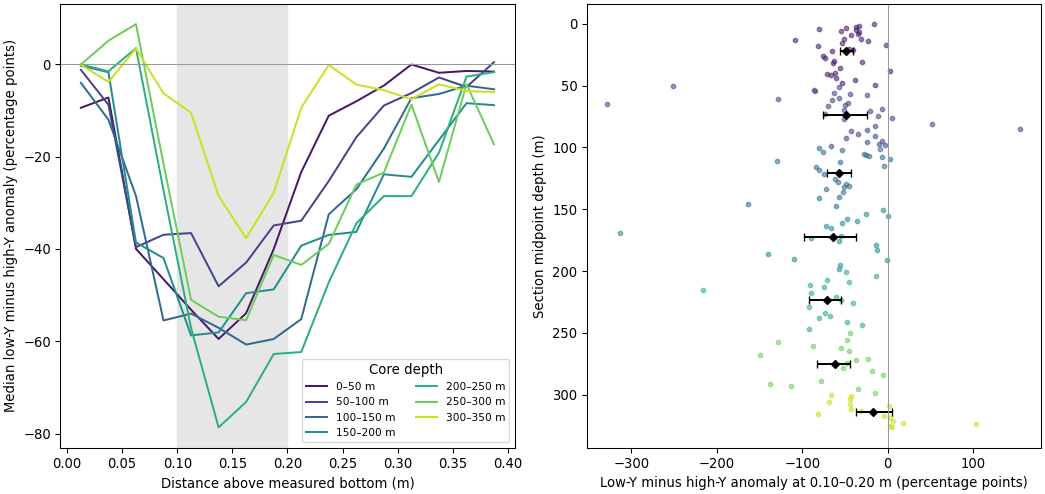

In [4]:
fig,axes = plt.subplots(1,2,figsize=(11,5.2),layout='constrained')
colors = plt.get_cmap('viridis')(np.linspace(.06,.92,len(summary)))
for (band,g),color in zip(pairs.groupby('band'),colors):
    near = g[g.bottom.between(0,.40,inclusive='left')].copy()
    near['position'] = (np.floor(near.bottom/.025)+.5)*.025
    profile = near.groupby(['section','position']).gap.mean().groupby('position').agg(['median','count'])
    profile = profile[profile['count']>=3]
    axes[0].plot(profile.index,profile['median'],color=color,label=f'{band}–{band+50} m')
    pts = section[section.band==band]
    axes[1].scatter(pts.gap,pts.depth,s=11,color=color,alpha=.55)
    row = summary.loc[band]
    axes[1].errorbar(row.gap,pts.depth.mean(),xerr=[[row.gap-row.lower],[row.upper-row.gap]],
                     fmt='D',color='black',capsize=3,ms=4)
axes[0].axhline(0,color='.6',linewidth=.8)
axes[0].axvspan(.10,.20,color='.9',zorder=-1)
axes[0].legend(title='Core depth',fontsize=8,ncol=2)
axes[0].set(xlabel='Distance above measured bottom (m)',ylabel='Median low-Y minus high-Y anomaly (percentage points)')
axes[1].axvline(0,color='.6',linewidth=.8)
axes[1].invert_yaxis()
axes[1].set(xlabel='Low-Y minus high-Y anomaly at 0.10–0.20 m (percentage points)',ylabel='Section midpoint depth (m)')
fig.savefig(figdir/'dc_anomaly_by_50m.png',dpi=180)
plt.show()

Scans in acquisition order: 52 66
          n   low  high   gap  median  lower  upper  negative
first  42.0 -61.4  -6.4 -55.0   -53.4  -67.8  -44.8      41.0
last   60.0 -51.8   0.4 -52.3   -48.0  -64.3  -40.1      53.0
Last minus first mean difference, 95% interval: 2.8 [-13.9  19.9]
Scans in acquisition order: 20 20
          n   low  high   gap  median  lower  upper  negative
first  16.0 -53.9 -11.1 -42.8   -36.8  -55.4  -31.8      16.0
last   20.0 -25.9   3.3 -29.2   -33.1  -51.3   -6.5      13.0
Last minus first mean difference, 95% interval: 13.6 [-11.5  39.2]
Last-week scans by midpoint depth:
          n   low  high   gap  median  lower  upper  negative
False  44.0 -65.1  -0.3 -64.8   -55.5  -77.9  -52.8      44.0
True   16.0 -15.4   2.3 -17.7   -17.6  -37.9    4.4       9.0
Final scans in order:
         depth    gap
section              
307      295.0  -35.2
310      298.2  -15.0
312      300.3  -66.5
313      301.4  -42.6
315      303.5  -43.6
317      305.5  -68.1
319     

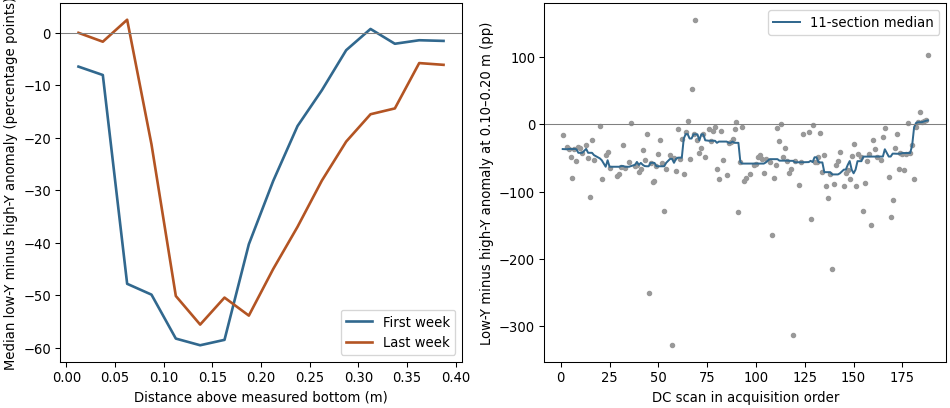

In [5]:
ordered = info.sort_values('date')
week = ordered.date.dt.to_period('W-SUN')
first_week = ordered[week==week.iloc[0]]
last_week = ordered[week==week.iloc[-1]]
def phase(g):
    return section[section.index.isin(g.index)]
def compare_periods(early,late):
    a,b = phase(early),phase(late)
    print('Scans in acquisition order:',len(early),len(late))
    print(pd.DataFrame({'first':summarize(a),'last':summarize(b)}).T.round(1))
    diff = (rng.choice(b.gap,(10000,len(b)),replace=True).mean(axis=1)
            -rng.choice(a.gap,(10000,len(a)),replace=True).mean(axis=1))
    print('Last minus first mean difference, 95% interval:',round(b.gap.mean()-a.gap.mean(),1),np.quantile(diff,[.025,.975]).round(1))
compare_periods(first_week,last_week)
compare_periods(ordered.head(20),ordered.tail(20))
last = phase(last_week)
print('Last-week scans by midpoint depth:')
print(pd.DataFrame({str(k):summarize(g) for k,g in last.groupby(last.depth>=300)}).T.round(1))
print('Final scans in order:')
print(phase(ordered.tail(18)).sort_values('date')[['depth','gap']].round(1))
fig,axes=plt.subplots(1,2,figsize=(10,4.3),layout='constrained')
for group,label,color in [(first_week,'First week','#31688e'),(last_week,'Last week','#b35423')]:
    g=pairs[pairs.section.isin(group.index)&pairs.bottom.between(0,.40)].copy()
    g['position']=(np.floor(g.bottom/.025)+.5)*.025
    profile=g.groupby(['section','position']).gap.mean().groupby('position').median()
    axes[0].plot(profile.index,profile,label=label,color=color,lw=2)
order=pd.Series(np.arange(1,len(ordered)+1),index=ordered.index)
s=section.join(order.rename('order')).sort_values('order')
axes[1].scatter(s.order,s.gap,s=10,color='0.60')
axes[1].plot(s.order,s.gap.rolling(11,center=True,min_periods=6).median(),color='#31688e',label='11-section median')
for ax in axes:
    ax.axhline(0,color='0.5',lw=.8)
    ax.legend()
axes[0].set(xlabel='Distance above measured bottom (m)',ylabel='Median low-Y minus high-Y anomaly (percentage points)')
axes[1].set(xlabel='DC scan in acquisition order',ylabel='Low-Y minus high-Y anomaly at 0.10–0.20 m (pp)')
fig.savefig(figdir/'dc_anomaly_first_last_week.png',dpi=180)
plt.show()